# Random Forest Algorithm

The Random Forest algorithm is a powerful ensemble machine learning method used for both classification (predicting a category) and regression (predicting a continuous number) tasks. Instead of relying on a single decision tree, it constructs a "forest" of multiple independent decision trees during training and merges their predictions together. This collective approach significantly improves accuracy and controls the risk of overfitting.   The final decision is made by taking a majority vote (for classification) or an average (for regression).


## How the Random Forest Works
The algorithm injects randomness into the training process in two distinct ways, a technique known as Bagging (Bootstrap Aggregating) combined with Feature Sampling: 

   1. **Bootstrap Sampling (Data Level)**: The algorithm creates a unique training dataset for each individual tree by randomly sampling rows from the original data with replacement. This means some data points are repeated (i.e., duplicate rows of data) in a sample, while roughly one-third are left out (known as Out-of-Bag or OOB data, used later for internal validation). 
   
   2. **Random Feature Selection (Feature Level)**: When building nodes within a tree, the algorithm does not look at all available columns (features). Instead, it picks a random subset of features to find the best split.
      * Classification rule of thumb: It typically samples $\sqrt{\text{total features}}$.
      * Regression rule of thumb: It typically samples $\frac{1}{3}$ of the total features. 
   
   3. **Independent Tree Growth**: Each individual decision tree is grown to its maximum depth without pruning, learning specific data patterns from its unique subset of data and features.
   
   4. **Aggregation**: When a new data point needs to be predicted, it is run through every single tree in the forest.
      * For Classification: The final output is decided by a majority vote (the class predicted most often).
      * For Regression: The final output is the average (mean) of all the individual tree predictions. 
   

> Bootsrapping the data plus using the aggregate to make a decision is called **Bagging**.

## Direct Comparison: Decision Tree vs. Random Forest

| Feature | Single Decision Tree | Random Forest |
|---|---|---|
| Structure | A single flow-chart-like tree structure. | An ensemble collection of tens or hundreds of individual trees. |
| Variance / Overfitting | High variance. Prone to overfitting by memorizing training data noise. | Low variance. Randomness "decorrelates" trees, drastically reducing overfitting. |
| Interpretability | Highly interpretable; easy to visualize the exact decision path. | "Black box" model; hard to track every decision path, but provides Feature Importance metrics. |
| Data Sensitivity | Small changes in training data can completely alter the tree structure. | Highly robust; minor data shifts don't heavily disrupt the entire forest. |


## Advantages & Disadvantages

### Advantages

* **High Accuracy & Generalization**: Combining multiple independent trees averages out individual errors, boosting overall accuracy.
* **No Feature Scaling Required**: It handles raw data directly without needing normalization or standardization. 
* **Handles High-Dimensional Data**: It excels at managing vast datasets with hundreds of features without losing performance. 
* **Built-in Feature Importance**: It automatically ranks which data variables contributed the most to the final predictions. 

### Disadvantages

* **Computationally Expensive**: Training hundreds of trees and making real-time predictions requires significant memory and CPU power. 
* **Slower Predictions**: It is not always ideal for ultra-low latency, real-time application environments because every tree must compute a result before aggregation. 
* **Complex Interpretability**: While you can see which features matter, you lose the simple step-by-step logic map provided by a single decision tree.

### Random forest applications

The random forest algorithm has been applied across a number of industries, allowing them to make better business decisions. Some use cases include:

* Finance: It is a preferred algorithm over others as it reduces time spent on data management and pre-processing tasks. It can be used to evaluate customers with high credit risk, to detect fraud, and option pricing problems.


* Healthcare: The random forest algorithm has applications within computational biology, allowing doctors to tackle problems such as gene expression classification, biomarker discovery, and sequence annotation. As a result, doctors can make estimates around drug responses to specific medications.


* E-commerce: It can be used for recommendation engines for cross-sell purposes.



#### ⚙️ Key Hyperparameters Explained

| Parameter | What It Controls | Real-World Analogy | Impact on Model |
| --- | --- | --- | --- |
| **`n_estimators`** | The total number of decision trees in the forest. | The size of the panel of experts you consult. | Higher values generally improve accuracy and stability, but increase training and prediction time. |
| **`max_features`** | The maximum number of features evaluated at each split. | Restricting each expert to only look at a random selection of clues. | Prevents a few dominant features from dictating every tree's decisions, increasing diversity. |
| **`min_samples_leaf`** | The minimum number of samples required to be at a leaf node (end of a branch). | Setting a rule that an expert cannot make a final call based on just 1 or 2 isolated cases. | Larger values stop trees from growing too deep and memorizing noise, preventing overfitting. |

#### 🔍 Fine-Tuning Trade-offs

| Parameter | Setting It Too Low | Setting It Too High |
| --- | --- | --- |
| **`n_estimators`** | High variance; predictions may be unstable and noisy. | Diminishing performance gains while slowing down computations. |
| **`max_features`** | Trees become too different and individually weak; risk of underfitting. | Trees become highly correlated and too similar to one another. |
| **`min_samples_leaf`** | Trees grow deep, learning noisy details (**overfitting**). | Trees stop growing too early, missing real patterns (**underfitting**). |


#### Create a Python script using Matplotlib and Scikit-Learn that plots validation curves for n_estimators and min_samples_leaf to visualize overfitting.


A **Validation Curve** is one of the best visual tools in machine learning to diagnose **overfitting** and **underfitting**. It shows how training performance and cross-validation performance change as you tune a single hyperparameter.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import validation_curve

# Generate a synthetic classification dataset
X, y = make_classification(
    n_samples=1000, 
    n_features=20, 
    n_informative=15, 
    n_redundant=5, 
    random_state=42
)

# 1. Validation Curve for min_samples_leaf
param_range_leaf = [1, 2, 5, 10, 20, 50, 100]
train_scores_leaf, test_scores_leaf = validation_curve(
    RandomForestClassifier(n_estimators=100, random_state=42),
    X, y,
    param_name="min_samples_leaf",
    param_range=param_range_leaf,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

train_mean_leaf = np.mean(train_scores_leaf, axis=1)
test_mean_leaf = np.mean(test_scores_leaf, axis=1)

print("Leaf validation curve complete.")
print("Train scores:", train_mean_leaf)
print("Test scores:", test_mean_leaf)


Leaf validation curve complete.
Train scores: [1.      0.99925 0.98875 0.96275 0.927   0.8675  0.81975]
Test scores: [0.916 0.91  0.899 0.887 0.855 0.815 0.774]


##### 💡 The Intuition: Practice Tests vs. Real Exams

Imagine studying for an exam:

* **Training Score (Practice Tests):** How well you answer questions you have already studied with the answer key open.
* **Validation Score (Real Exam):** How well you answer new, unseen questions on exam day.

When you plot both scores against a hyperparameter, you see three distinct zones:

1. **Overfitting Zone:** The training score is nearly 100%, but the validation score drops or lags behind. The large gap means the model memorized the training noise instead of learning general patterns.
2. **Underfitting Zone:** Both training and validation scores are low. The model is too restricted to learn the underlying relationships.
3. **Sweet Spot:** The point where validation score reaches its peak and the gap between training and validation accuracy is safely minimized.



##### 📊 Comparing `min_samples_leaf` vs. `n_estimators`

| Parameter | Core Idea | When Set Low | When Set High | Overfitting Behavior |
| --- | --- | --- | --- | --- |
| **`min_samples_leaf`** | Minimum samples required at a leaf node. | Deep trees that fit every tiny detail. | Shallow trees that force generalized rules. | **High risk when low** (`min_samples_leaf=1` lets trees memorize individual noisy data points). |
| **`n_estimators`** | Total number of trees in the forest. | High variance; forest is sensitive to small noise. | Ensemble stabilizes; performance plateaus. | **Low risk when high** (Adding more trees rarely overfits; it just hits diminishing returns). |


##### 🔬 Anatomy of a Validation Curve

When reading validation curve plots:

* **X-Axis:** The value of the hyperparameter being tuned (e.g., number of trees or minimum leaf size).
* **Y-Axis:** Evaluation metric (e.g., Accuracy score).
* **Blue Line (Training Score):** Indicates training accuracy across cross-validation folds.
* **Orange Line (Validation Score):** Indicates test accuracy on held-out validation folds.
* **Shaded Band:** Represents standard deviation ($\pm 1 \sigma$) across cross-validation splits.

Here is a complete, runnable script using `sklearn.model_selection.validation_curve` and `matplotlib` to plot validation curves for both parameters side-by-side:


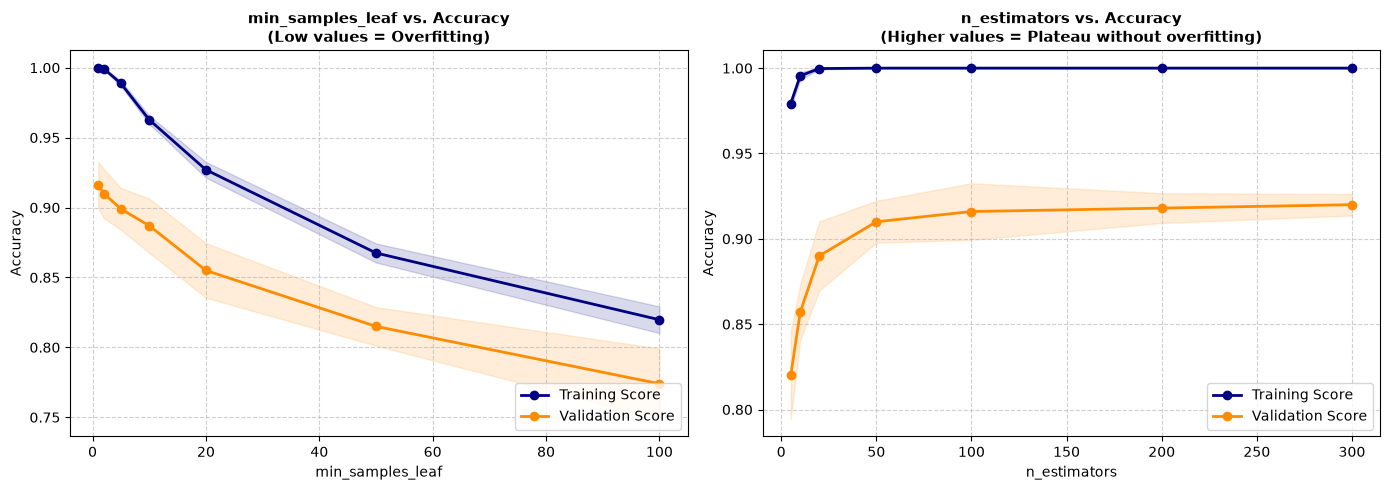

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import validation_curve

# 1. Create a synthetic dataset with realistic noise
X, y = make_classification(
    n_samples=1000, 
    n_features=20, 
    n_informative=15, 
    n_redundant=5, 
    random_state=42
)

# Initialize base classifier
rf = RandomForestClassifier(random_state=42)

# Define parameter search ranges
leaf_range = [1, 2, 5, 10, 20, 50, 100]
trees_range = [5, 10, 20, 50, 100, 200, 300]

# 2. Compute validation curve data for min_samples_leaf
train_scores_leaf, test_scores_leaf = validation_curve(
    estimator=rf, X=X, y=y,
    param_name="min_samples_leaf",
    param_range=leaf_range,
    cv=5, scoring="accuracy", n_jobs=-1
)

# 3. Compute validation curve data for n_estimators
train_scores_trees, test_scores_trees = validation_curve(
    estimator=rf, X=X, y=y,
    param_name="n_estimators",
    param_range=trees_range,
    cv=5, scoring="accuracy", n_jobs=-1
)

# Helper function to render a validation curve
def plot_validation_curve(ax, param_range, train_scores, test_scores, xlabel, title):
    # Calculate mean and standard deviation across CV folds
    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    test_mean = np.mean(test_scores, axis=1)
    test_std = np.std(test_scores, axis=1)

    # Plot training score
    ax.plot(param_range, train_mean, label="Training Score", color="navy", lw=2, marker="o")
    ax.fill_between(param_range, train_mean - train_std, train_mean + train_std, alpha=0.15, color="navy")

    # Plot validation score
    ax.plot(param_range, test_mean, label="Validation Score", color="darkorange", lw=2, marker="o")
    ax.fill_between(param_range, test_mean - test_std, test_mean + test_std, alpha=0.15, color="darkorange")

    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel("Accuracy", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend(loc="lower right")

# 4. Plot both validation curves side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

plot_validation_curve(
    ax1, leaf_range, train_scores_leaf, test_scores_leaf, 
    xlabel="min_samples_leaf", 
    title="min_samples_leaf vs. Accuracy\n(Low values = Overfitting)"
)

plot_validation_curve(
    ax2, trees_range, train_scores_trees, test_scores_trees, 
    xlabel="n_estimators", 
    title="n_estimators vs. Accuracy\n(Higher values = Plateau without overfitting)"
)

plt.tight_layout()
plt.show()


##### What You Will Notice in the Output:

1. **Left Plot (`min_samples_leaf`):** At `min_samples_leaf=1`, training accuracy is 100% while validation accuracy is lower—a classic **overfitting gap**. As `min_samples_leaf` increases toward 5–10, the gap shrinks and validation accuracy reaches its peak.
2. **Right Plot (`n_estimators`):** Starting with very few trees (e.g., 5 or 10) gives lower performance. As you increase `n_estimators`, both training and validation accuracy rise together and level off near 100 trees without widening the gap.


## [Statsquest: Random Forests Part 2: Missing data and clustering ](https://youtu.be/mIlw5j3WyVk?si=x08WCowG8j7pDZtX)

![](images/rf1.png)

### Case 1: Missing Data in original dataset used to create the random forest

![](images/rf2.png)

Because this person did not have heart disease, the initial and possibly bad guess for the blocked arteries value is just the most common value for blocked arteries found in the other samples that do not have heart disease. Among the people that do not have heart disease, no is the most common value for blocked arteries. It occurs in two out of two samples. **So no is our initial guess**.


Since weight is numeric, our initial guess will be the median value of the patients that did not have heart disease. In this case, **the median value is 167.5**.   
Here's our new data set with the filledin missing values.

![](images/rf3.png)

- Step one, build a random forest. 
- Step two, run all of the data down all of the trees. 


We'll start by running all of the data down the first tree. Notice that sample three and sample 4 both ended up at the same leaf node. That means they're similar. At least that's how similarity is defined in random forests. 

![](images/rf4.png)


> We keep track of similar samples using a `proximity matrix`. The **proximity matrix** has a row for each sample. and it has a column for each sample. 


Because sample three and sample four ended up in the same leaf node, we put a one here. 

![](images/rf5.png)

Since this position also represents samples three and four because no other pair of samples ended in the same leaf node, our proximity matrix looks like this.

![](images/rf6.png)







Now, we run all data down the 2nd decision tree (Remember the different decision tree in random forest depends on the features and sample data considered).

![](images/rf7.png)

![](images/rf8.png)

![](images/rf9.png)

Ultimately, we run the data down all the trees and the proximity matrix fills in. Then we divide each proximity value by the total number of trees. In this example, assume we had 10 trees. Now we use the proximity values for sample four to make better guesses about the missing data.

![](images/rf10.png)


| | Sample 1 | Sample 2 | Sample 3 |
|---|---|---|---|
| **Proximity to sample 4** | 0.1 | 0.1 | 0.8 |
| **Blocked Arteries** | No | Yes | No |


Nr is the proximity value.  
Dr is the number of same categorical variables (Yes/No). 

![](images/rf11.png)


For weight, we use the proximities to calculate a weighted average. In this case, the weighted average equals sample one's weight sample one's weighted average weight. 

![](images/rf12.png)

![](images/rf13.png)

![](images/rf14.png)

## Proximity Matrix Visualization

![](images/rf15.png)

![](images/rf16.png)




![](images/rf17.png)

## Clustering

![](images/rf18.png)

![](images/rf19.png)

![](images/rf20.png)

![](images/rf21.png)

![](images/rf22.png)



## Clustering in Random Forest

#### Worked example: refining the guess for `Blocked Arteries` (and `Weight`) using the proximity matrix

**Step 1: Read sample 4's row of the proximity matrix.** After 10 trees, each proximity has been divided by 10. The diagonal (sample 4 compared with itself) is ignored.

| | Sample 1 | Sample 2 | Sample 3 |
|---|---|---|---|
| **Proximity to sample 4** | 0.1 | 0.1 | 0.8 |
| **Blocked Arteries** | No | Yes | No |
| **Weight** | 125 | 180 | 210 |

Sample 4 landed in the same leaf as sample 3 in 8 of the 10 trees, and with samples 1 and 2 in only 1 tree each. **Sample 3 is its closest neighbour.**

**Step 2: Turn proximities into a weight per category.**

$$
w(\text{category}) = \frac{\sum_{j \,\in\, \text{category}} \text{prox}(4, j)}{\sum_{\text{all } j} \text{prox}(4, j)}
$$

The denominator is $0.1 + 0.1 + 0.8 = 1.0$.

- **Yes:** only sample 2 has Yes, so $w(\text{Yes}) = \dfrac{0.1}{1.0} = 0.1$
- **No:** samples 1 and 3 have No, so $w(\text{No}) = \dfrac{0.1 + 0.8}{1.0} = 0.9$

**Step 3: Weighted frequency of each category = frequency × weight.**

| Category | Frequency | × Weight | = Weighted frequency |
|---|---|---|---|
| Yes | $\frac{1}{3}$ | 0.1 | $\approx 0.03$ |
| No | $\frac{2}{3}$ | 0.9 | $= 0.60$ |

**No** has the higher weighted frequency, so the updated guess for Blocked Arteries is **No**. Intuitively, sample 3 has Blocked Arteries = No and is the sample most similar to sample 4, so it gets most of the vote.

**Same idea for `Weight` (numeric column): a proximity-weighted average.**

$$
\hat{x}_4 = \sum_j x_j \cdot \frac{\text{prox}(4,j)}{\sum_k \text{prox}(4,k)}
= 125(0.1) + 180(0.1) + 210(0.8) = 12.5 + 18 + 168 = \mathbf{198.5}
$$

The first guess of 167.5 (the median) moves up toward sample 3's weight of 210.

**Step 4: Iterate.**
1. Put the new values (No, 198.5) into the table.
2. Build a new random forest and run all the data down its trees.
3. Recompute the proximity matrix and recompute the guesses.
4. Repeat about 6–7 times, or until the guesses stop changing (converge).

> **Note:** Multiplying the frequency by the proximity weight is how StatQuest presents it, but it counts how common a category is twice, because the weight already sums over that category's samples. Breiman's original method simply picks the category with the **largest summed proximity**: Yes = 0.1, No = 0.9, so No. Both methods give the same answer here, and Breiman's version is the cleaner one to explain.

In [1]:
import numpy as np

# Row 4 of the proximity matrix (already divided by 10 trees), excluding the diagonal
prox_4 = np.array([0.1, 0.1, 0.8])           # sample 4 vs samples 1, 2, 3
blocked = np.array(["No", "Yes", "No"])
weight = np.array([125, 180, 210])

w = prox_4 / prox_4.sum()                    # normalise so the proximities sum to 1

# Categorical: StatQuest's "frequency x weight" score
for cat in ["Yes", "No"]:
    mask = blocked == cat
    freq = mask.mean()
    print(f"{cat}: frequency={freq:.3f}, weight={w[mask].sum():.1f}, weighted frequency={freq * w[mask].sum():.3f}")

# Breiman's version: category with the largest summed proximity
print("Summed proximity -> Yes:", prox_4[blocked == "Yes"].sum(), "| No:", prox_4[blocked == "No"].sum())

# Numeric: proximity-weighted average
print("Weight guess:", (weight * w).sum())

Yes: frequency=0.333, weight=0.1, weighted frequency=0.033
No: frequency=0.667, weight=0.9, weighted frequency=0.600
Summed proximity -> Yes: 0.1 | No: 0.9
Weight guess: 198.5
